In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import torchvision
import torchvision.datasets as datasets
from torchvision.transforms import ToTensor

from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
# import datasets
training_data = datasets.MNIST(
    root="../data",
    train=True,
    download=False,
    transform=ToTensor()
)

test_data = datasets.MNIST(
    root="../data",
    train=False,
    download=False,
    transform=ToTensor()
)

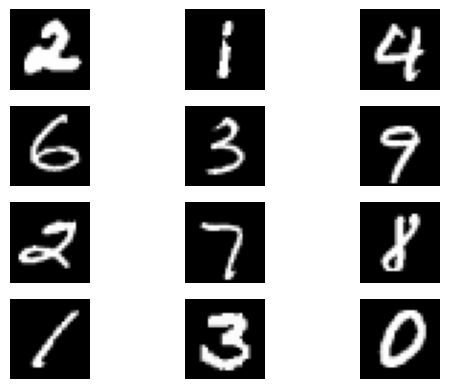

In [3]:
figure = plt.figure()
cols, rows = 3,4
for i in range (1, cols * rows+1):
    sample_index = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_index]
    figure.add_subplot(rows, cols, i)
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [4]:
image, label = training_data[0]

print(image.shape)
print(label)
print(type(image))
print(type(label))
print(len(training_data))

torch.Size([1, 28, 28])
5
<class 'torch.Tensor'>
<class 'int'>
60000


In [5]:
image, label = test_data[0]

print(image.shape)
print(label)
print(type(image))
print(type(label))
print(len(test_data))

torch.Size([1, 28, 28])
7
<class 'torch.Tensor'>
<class 'int'>
10000


### Dataloader
A dataloader passes the data in "minibatches", so it prepares the data before training and randomly reorders the data before each training pass (epoch)

In [6]:
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

### Train CNN model
Below the following is defined:
- `in_channels`=1, as the image.shape gave [**1**,28,28], **1** is the channel
- `out_channels`=32, number of filters the model will learn, produce 32 feature maps
- `kernel_size`=3, tells the model to look at 3x3 region of the image at a time

The new shape `(32,26,26)` is defined below:
- **32**: is the number of output channels
- **26x26**: 
    - Kernel size = **3 × 3**
    - Stride = **1**
    - Padding = **0** (no padding)

    The output size is calculated as:

    $$
    \text{Output Size} =
    \frac{\text{Input Size} - \text{Kernel Size} + 2(\text{Padding})}{\text{Stride}} + 1
    $$

- `self.pool`, a pooling window of size 2x2 looks at a small section and takes the maximum value. This helps reduce the amount of data passed to the later layers, retians the strong features and reduce computation


In [7]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # convolational layer
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3
        ) # (32,26,26) new shape

        self.pool = nn.MaxPool2d(2,2) # (32, 13, 13)

        # 2nd convolational layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=5
        ) # (64, 9, 9)

        # call pool again then, the new shape would be (64, 4, 4)

        # flatten the shape, 64 * 4 * 4

        self.fcl1 = nn.Linear(64 * 4 * 4, 120)
        self.fcl2 = nn.Linear(120, 84)
        self.fcl3 = nn.Linear(84,10) # needs to have 10 here, as MNIST classification has 10 possible classes

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x))
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

In [8]:
net = CNN() # creates an instance of the neural network defined above
loss_function = nn.CrossEntropyLoss() # tells us how wrong the model's predictions are
optimiser = optim.SGD(
    net.parameters(), 
    lr=0.001, 
    momentum=0.9
) # updates the models weights, uses the gradients calculated from the loss to update the weights

In [9]:
for epoch in range (20):
    print(f'Training epoch {epoch} .. ')

    running_loss=0.0 # count the running loss

    for i, data in enumerate(train_dataloader):
        inputs, labels = data # split data into inputs -> images and labels -> correct answers

        optimiser.zero_grad() # clears the gradients from the prev batch

        outputs = net(inputs)

        loss = loss_function(outputs, labels)
        loss.backward() # calculate new gradients 
        optimiser.step() # use those gradients to update weights

        running_loss += loss.item()

    print(f'Loss: {running_loss / len(train_dataloader):.4f}')

Training epoch 0 .. 
Loss: 1.9206
Training epoch 1 .. 
Loss: 0.3846
Training epoch 2 .. 
Loss: 0.2170
Training epoch 3 .. 
Loss: 0.1527
Training epoch 4 .. 
Loss: 0.1210
Training epoch 5 .. 
Loss: 0.1032
Training epoch 6 .. 
Loss: 0.0902
Training epoch 7 .. 
Loss: 0.0808
Training epoch 8 .. 
Loss: 0.0750
Training epoch 9 .. 
Loss: 0.0683
Training epoch 10 .. 
Loss: 0.0637
Training epoch 11 .. 
Loss: 0.0590
Training epoch 12 .. 
Loss: 0.0562
Training epoch 13 .. 
Loss: 0.0537
Training epoch 14 .. 
Loss: 0.0492
Training epoch 15 .. 
Loss: 0.0471
Training epoch 16 .. 
Loss: 0.0450
Training epoch 17 .. 
Loss: 0.0426
Training epoch 18 .. 
Loss: 0.0402
Training epoch 19 .. 
Loss: 0.0387


In [11]:
torch.save(net.state_dict(), 'trained_net.pth')

In [13]:
net = CNN()
net.load_state_dict(torch.load('trained_net.pth'))

<All keys matched successfully>

In [20]:
correct = 0 # how many are correct
total = 0 # how many were tested

net.eval() # tells pytorch that the model is being tested not trained

# no gradient updates needed as we are testing the model now
with torch.no_grad():
    for data in test_dataloader:
        images, labels = data # test images and correct answers
        outputs = net(images)
        # we only care about the index, torch.max(..) retruns 2 things, maximun value and the index 
        _, predicted = torch.max(outputs, 1) # find the maximum across the 10 class outputs 
        total += labels.size(0) 
        correct += (predicted == labels).sum().item()

accuracy = 100* correct / total

print(f'Accuracy: {accuracy}%')

Accuracy: 98.58%


Predicted: 7
Actual: 7


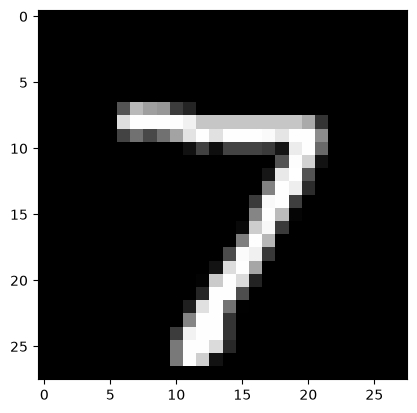

In [31]:
#image = image.unsqueeze(0) # changes the shape to [batch, channels, height, width] -> [1,1,28,28]

net.eval()

with torch.no_grad():
    output = net(image)
    _,predicted = torch.max(output,1)

print("Predicted:", predicted.item())
print("Actual:", label)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()